In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uniguide.config import get_path, load_config
from uniguide.data.stats import save_fig
from uniguide.evaluation.beyond_accuracy import (
    ItemSimilarity, evaluate_beyond_accuracy, evaluation_users, popularity_from_train)
from uniguide.models.content_based import ContentBasedRecommender
from uniguide.models.embeddings import ContentFusionRecommender, EmbeddingContentRecommender
from uniguide.models.popularity import PopularityRecommender

cfg = load_config()
p = get_path("processed")
tables = get_path("results") / "tables"
train, val, test = (pd.read_parquet(p / f"{n}.parquet") for n in ["train", "val", "test"])
courses = pd.read_parquet(p / "courses.parquet")
cold_courses = set(json.loads((p / "cold_courses.json").read_text()))
courses_warm = courses[~courses["course_id"].isin(cold_courses)].reset_index(drop=True)
K = tuple(cfg["evaluation"]["k_values"])
train_val = pd.concat([train, val])
catalog = courses_warm["course_id"].tolist()

users = evaluation_users(test)
print(len(users))   # must equal the number of evaluated users of the accuracy results (14039)

14039


In [2]:
BEST_Q = 0.99        # <- from notebook 03 (update after extending the grid)
NAME_WEIGHT = 0.5    # <- from notebook 04b

models = {
    "popularity": PopularityRecommender(m_quantile=BEST_Q),
    "content_based": ContentBasedRecommender(),
    "content_embeddings": EmbeddingContentRecommender(name_weight=NAME_WEIGHT),
    "content_fusion": ContentFusionRecommender(
        [ContentBasedRecommender(), EmbeddingContentRecommender(name_weight=NAME_WEIGHT)]),
}
# Person B's models, with the hyperparameters they selected on validation:
# from uniguide.models.collaborative import CollaborativeRecommender
# from uniguide.models.hybrid import HybridRecommender
# models["collaborative"] = CollaborativeRecommender(method="knn", n_neighbors=...)
# models["hybrid"] = HybridRecommender(ContentBasedRecommender(),
#                                      CollaborativeRecommender(method="knn"), alpha=...)

for model in models.values():
    model.fit(train_val, courses_warm)

In [3]:
sim_tfidf = ItemSimilarity.from_content_model(models["content_based"])
sim_emb = ItemSimilarity.from_content_model(models["content_embeddings"])
popularity = popularity_from_train(train_val, catalog)

In [4]:
frames = []
for model in models.values():
    r1 = evaluate_beyond_accuracy(model, users, sim_tfidf, popularity, set(catalog),
                                  K, "main", cfg["seed"])
    r2 = evaluate_beyond_accuracy(model, users, sim_emb, popularity, set(catalog),
                                  K, "main", cfg["seed"])
    r2 = r2[r2["metric"] == "diversity"].assign(metric="diversity_emb")
    frames.append(pd.concat([r1, r2]))
beyond = pd.concat(frames)
beyond.to_csv(tables / "eval_beyond_accuracy.csv", index=False)

In [5]:
def summarize(df):
    return df.groupby(["method", "k", "metric"])["value"].mean().unstack("metric")

acc_files = [f for f in tables.glob("eval_*.csv") if f.name != "eval_beyond_accuracy.csv"]
acc = pd.concat([pd.read_csv(f) for f in acc_files])
acc = acc[acc["experiment"] == "main"]

table = summarize(acc).join(summarize(beyond), how="outer")
cols = ["ndcg", "hit_rate", "precision", "recall",
        "coverage", "diversity", "diversity_emb", "novelty"]
final = table.xs(10, level="k")[cols].round(3)
final.to_csv(tables / "comparison_k10.csv")
final

metric,ndcg,hit_rate,precision,recall,coverage,diversity,diversity_emb,novelty
method,,,,,,,,
content_based,0.097,0.204,0.022,0.159,0.966,0.884,0.449,5.930
content_embeddings,0.097,0.218,0.024,0.167,0.955,0.913,0.357,5.479
content_fusion,0.108,0.226,0.024,0.178,0.979,0.893,0.392,5.581
popularity,0.109,0.279,0.033,0.197,0.061,0.929,0.469,3.439


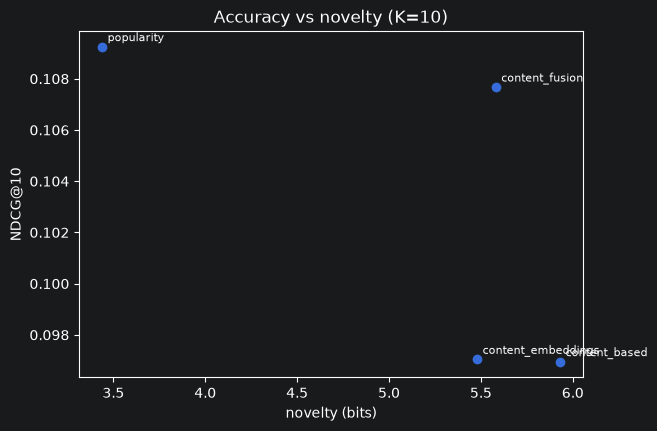

In [6]:
t = table.xs(10, level="k")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(t["novelty"], t["ndcg"])
for method, row in t.iterrows():
    ax.annotate(method, (row["novelty"], row["ndcg"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="novelty (bits)", ylabel="NDCG@10", title="Accuracy vs novelty (K=10)")
save_fig(fig, "accuracy_vs_novelty")